# 04 · Final training, in-domain evaluation and zero-shot transfer

Protocol, identical for the four architectures:

* selected configuration from notebook 03, seeds 0, 1, 2;
* same training windows, same mini-batch order and augmentation draws for a given seed;
* BCE with positive-class weight `n_neg / n_pos`, AdamW, 1 warm-up epoch then cosine decay,
  batch 256, up to 15 epochs, early stopping on the SisFall validation loss (patience 4);
* decision threshold = the one maximising F2 on SisFall validation, reused unchanged on
  the SisFall test subjects and on Daphnet.

Daphnet is evaluated under three normalisations (source statistics, unlabeled domain
statistics, unlabeled per-subject statistics). The domain-statistics view is the main zero-shot
result.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve

sys.path.insert(0, str(Path.cwd().parent))
from src import config as C
from src.engine import predict_proba, train_model
from src.experiment import daphnet_views, load_all, load_scaler, sisfall_splits
from src.metrics import binary_metrics, bootstrap_auroc, fbeta_threshold
from src.models import build_model, count_params
from src.plotting import save, set_style

set_style()
X_sis, meta_sis, X_dap, meta_dap = load_all()
src_scaler, tgt_scaler = load_scaler("source"), load_scaler("target")
S = sisfall_splits(X_sis, meta_sis, src_scaler)
DV = daphnet_views(X_dap, meta_dap, src_scaler, tgt_scaler)
y_dap = meta_dap.label.values
best_hp = json.load(open(C.METRICS / "best_hparams.json"))
best_hp

{'CNN-1D': {'dropout': 0.5, 'kernel': 7, 'lr': 0.003, 'width': 32},
 'LSTM': {'bidirectional': True,
  'dropout': 0.3,
  'hidden': 64,
  'layers': 2,
  'lr': 0.001},
 'GRU': {'bidirectional': True,
  'dropout': 0.1,
  'hidden': 32,
  'layers': 2,
  'lr': 0.003},
 'Transformer': {'d_model': 64,
  'dropout': 0.2,
  'heads': 4,
  'layers': 2,
  'lr': 0.003,
  'patch': 8}}

## 1. Training (3 seeds x 4 architectures)

Checkpoints go to `models/<arch>/seed<k>.pt` together with the configuration, the scaler and
the validation threshold, so each file is enough to reproduce the predictions.

In [2]:
FINAL_CFG = {"epochs": 15, "patience": 4}
preds, histories, runs = {}, [], []
pred_path = C.METRICS / "predictions_04.npz"

for arch in C.ARCHS:
    hp = dict(best_hp[arch])
    lr = hp.pop("lr")
    for seed in C.SEEDS:
        ck = C.MODELS_DIR / arch.replace("-", "").lower() / f"seed{seed}.pt"
        ck.parent.mkdir(parents=True, exist_ok=True)
        t0 = time.time()
        if ck.exists():
            blob = torch.load(ck, weights_only=False, map_location="cpu")
            model = build_model(arch, hp)
            model.load_state_dict(blob["state_dict"])
            hist, info = blob["history"], blob["info"]
        else:
            model, hist, info = train_model(arch, hp, S["train"]["X_g"], S["train"]["y"],
                                            S["val"]["X"], S["val"]["y"], src_scaler,
                                            cfg={**FINAL_CFG, "lr": lr}, seed=seed, verbose=False)
        p_val = predict_proba(model, S["val"]["X"])
        thr = fbeta_threshold(S["val"]["y"], p_val, beta=2)
        if not ck.exists():
            torch.save({"arch": arch, "hp": hp, "lr": lr, "seed": seed, "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                        "threshold": thr, "scaler": src_scaler.state(), "history": hist, "info": info,
                        "channels": C.CHANNELS, "fs": C.FS, "window": C.WIN}, ck)
        preds[(arch, seed, "val")] = p_val
        preds[(arch, seed, "test")] = predict_proba(model, S["test"]["X"])
        for view, Xv in DV.items():
            preds[(arch, seed, view)] = predict_proba(model, Xv)
        for h in hist:
            histories.append({"arch": arch, "seed": seed, **h})
        runs.append({"arch": arch, "seed": seed, "threshold": thr, "params": count_params(model),
                     "best_epoch": info["best_epoch"], "epochs_run": len(hist),
                     "sec_per_epoch": float(np.mean([h["seconds"] for h in hist]))})
        print(f"{arch:12s} seed {seed}: best epoch {info['best_epoch']:2d}, thr {thr:.3f}, "
              f"test AUROC {roc_auc_score(S['test']['y'], preds[(arch, seed, 'test')]):.4f}, "
              f"Daphnet AUROC {roc_auc_score(y_dap, preds[(arch, seed, 'domain statistics')]):.4f} "
              f"({(time.time() - t0) / 60:.1f} min)", flush=True)

np.savez_compressed(pred_path, **{"|".join(map(str, k)): v for k, v in preds.items()})
runs = pd.DataFrame(runs)
hist_df = pd.DataFrame(histories)
runs.to_csv(C.METRICS / "final_runs.csv", index=False)
hist_df.to_csv(C.METRICS / "training_histories.csv", index=False)
runs

CNN-1D       seed 0: best epoch  2, thr 0.120, test AUROC 0.9849, Daphnet AUROC 0.4269 (0.1 min)


CNN-1D       seed 1: best epoch 11, thr 0.941, test AUROC 0.9900, Daphnet AUROC 0.5316 (0.1 min)


CNN-1D       seed 2: best epoch  4, thr 0.301, test AUROC 0.9875, Daphnet AUROC 0.5144 (0.1 min)


LSTM         seed 0: best epoch  9, thr 0.998, test AUROC 0.9995, Daphnet AUROC 0.5769 (0.8 min)


LSTM         seed 1: best epoch  4, thr 0.975, test AUROC 0.9996, Daphnet AUROC 0.5616 (0.8 min)


LSTM         seed 2: best epoch 11, thr 0.994, test AUROC 0.9991, Daphnet AUROC 0.6238 (0.8 min)


... (3 outputs left out)

Transformer  seed 0: best epoch  2, thr 0.991, test AUROC 0.9979, Daphnet AUROC 0.6613 (0.1 min)


Transformer  seed 1: best epoch  5, thr 0.982, test AUROC 0.9990, Daphnet AUROC 0.5970 (0.1 min)


Transformer  seed 2: best epoch 15, thr 0.999, test AUROC 0.9967, Daphnet AUROC 0.6009 (0.1 min)


,arch,seed,threshold,params,best_epoch,epochs_run,sec_per_epoch
0,CNN-1D,0,0.119780,36289,2,6,1.993802
1,CNN-1D,1,0.940677,36289,11,15,1.794067
2,CNN-1D,2,0.300824,36289,4,8,1.795752
3,LSTM,0,0.998157,135425,9,13,4.087184
4,LSTM,1,0.974899,135425,4,8,4.357266
5,LSTM,2,0.994197,135425,11,15,4.122464
6,GRU,0,0.988307,26241,11,15,2.279491
7,GRU,1,0.982284,26241,4,8,2.111238
8,GRU,2,0.992278,26241,14,15,2.191883
9,Transformer,0,0.991459,70401,2,6,2.787343


## 2. Learning curves

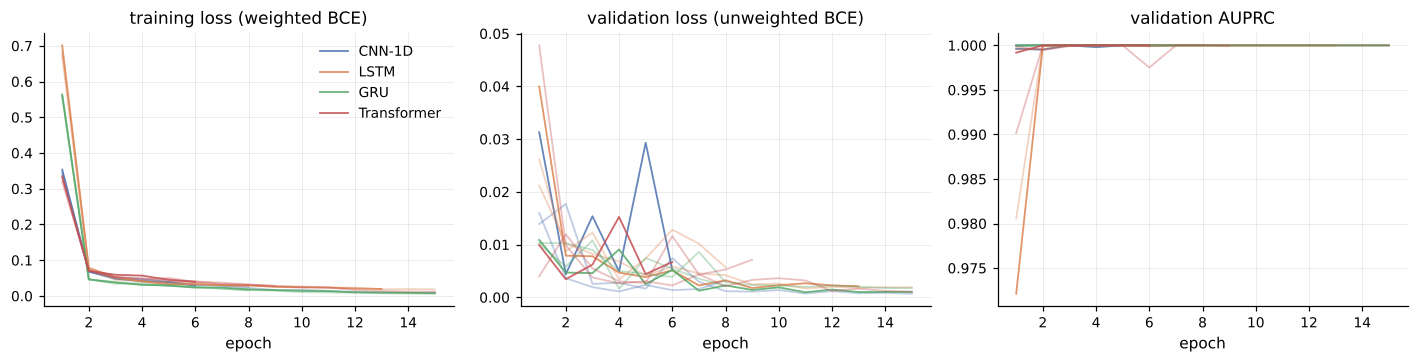

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for arch in C.ARCHS:
    for seed in C.SEEDS:
        h = hist_df[(hist_df.arch == arch) & (hist_df.seed == seed)]
        kw = dict(color=C.PALETTE[arch], alpha=0.85 if seed == 0 else 0.35, lw=1.2,
                  label=arch if seed == 0 else None)
        axes[0].plot(h.epoch, h.train_loss, **kw)
        axes[1].plot(h.epoch, h.val_loss, **kw)
        axes[2].plot(h.epoch, h.val_auprc, **kw)
axes[0].set_title("training loss (weighted BCE)")
axes[1].set_title("validation loss (unweighted BCE)")
axes[2].set_title("validation AUPRC")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].legend(frameon=False)
fig.tight_layout()
save(fig, "fig12_learning_curves")

## 3. In-domain results on the SisFall test subjects

In [4]:
def evaluate(split_key, y, groups=None):
    rows = []
    for arch in C.ARCHS:
        for seed in C.SEEDS:
            thr = runs[(runs.arch == arch) & (runs.seed == seed)].threshold.iloc[0]
            m = binary_metrics(y, preds[(arch, seed, split_key)], thr)
            # windows sit on a 1 s grid, so each negative window stands for one second of activity
            m["false_alarms_per_hour"] = m["fp"] / ((m["fp"] + m["tn"]) * C.STRIDE_SEC / 3600)
            rows.append({"arch": arch, "seed": seed, **m})
    return pd.DataFrame(rows)


def mean_std(df, cols):
    g = df.groupby("arch", sort=False)[cols]
    out = g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)
    return out.loc[C.ARCHS]


COLS = ["auroc", "auprc", "recall", "specificity", "precision", "f1", "f2", "balanced_acc",
        "recall_at_10fpr", "false_alarms_per_hour"]
res_test = evaluate("test", S["test"]["y"])
res_test.to_csv(C.METRICS / "sisfall_test_per_seed.csv", index=False)
tab_test = mean_std(res_test, COLS)
tab_test.to_csv(C.METRICS / "sisfall_test_summary.csv")
tab_test

,auroc,auprc,recall,specificity,precision,f1,f2,balanced_acc,recall_at_10fpr,false_alarms_per_hour
arch,,,,,,,,,,
CNN-1D,0.9875 ± 0.0026,0.9805 ± 0.002,0.9799 ± 0.0015,0.9996 ± 0.0003,0.9843 ± 0.0113,0.982 ± 0.0061,0.9807 ± 0.0031,0.9897 ± 0.0009,0.9843 ± 0.0,1.524 ± 1.1072
LSTM,0.9994 ± 0.0003,0.9904 ± 0.0023,0.9773 ± 0.0099,0.9998 ± 0.0,0.992 ± 0.0001,0.9846 ± 0.0051,0.9802 ± 0.008,0.9885 ± 0.005,0.9991 ± 0.0015,0.762 ± 0.0
GRU,0.9993 ± 0.0003,0.9916 ± 0.0016,0.9773 ± 0.003,0.9998 ± 0.0,0.9929 ± 0.0015,0.985 ± 0.002,0.9803 ± 0.0026,0.9885 ± 0.0015,0.9991 ± 0.0015,0.6773 ± 0.1466
Transformer,0.9979 ± 0.0012,0.9842 ± 0.0047,0.9589 ± 0.0099,0.9997 ± 0.0001,0.99 ± 0.0057,0.9742 ± 0.0079,0.965 ± 0.0091,0.9793 ± 0.005,0.9939 ± 0.0055,0.9313 ± 0.5288


## 4. Zero-shot transfer to Daphnet

In [5]:
res_dap = []
for view in DV:
    r = evaluate(view, y_dap)
    r["normalisation"] = view
    res_dap.append(r)
res_dap = pd.concat(res_dap, ignore_index=True)
res_dap.to_csv(C.METRICS / "daphnet_zero_shot_per_seed.csv", index=False)
main = res_dap[res_dap.normalisation == "domain statistics"]
tab_dap = mean_std(main, COLS)
tab_dap.to_csv(C.METRICS / "daphnet_zero_shot_summary.csv")
tab_dap

,auroc,auprc,recall,specificity,precision,f1,f2,balanced_acc,recall_at_10fpr,false_alarms_per_hour
arch,,,,,,,,,,
CNN-1D,0.491 ± 0.0561,0.1038 ± 0.0084,0.0092 ± 0.0085,0.9935 ± 0.0034,0.1296 ± 0.0606,0.017 ± 0.0152,0.0113 ± 0.0103,0.5014 ± 0.0032,0.1059 ± 0.0193,23.3478 ± 12.1657
LSTM,0.5874 ± 0.0324,0.124 ± 0.0209,0.0006 ± 0.0006,0.9962 ± 0.0003,0.016 ± 0.0161,0.0011 ± 0.0011,0.0007 ± 0.0007,0.4984 ± 0.0002,0.1126 ± 0.0947,13.6259 ± 0.9281
GRU,0.631 ± 0.042,0.143 ± 0.0231,0.0 ± 0.0,0.9967 ± 0.0014,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.4984 ± 0.0007,0.1869 ± 0.0735,11.7887 ± 5.054
Transformer,0.6197 ± 0.0361,0.1282 ± 0.0092,0.0002 ± 0.0003,0.9953 ± 0.0022,0.0031 ± 0.0053,0.0004 ± 0.0006,0.0002 ± 0.0004,0.4977 ± 0.0009,0.1388 ± 0.033,17.0707 ± 7.8092


In [6]:
ci_rows = []
for arch in C.ARCHS:
    p = np.mean([preds[(arch, s, "domain statistics")] for s in C.SEEDS], axis=0)
    lo, hi = bootstrap_auroc(y_dap, p, groups=meta_dap.subject.values, n_boot=1000)
    p_t = np.mean([preds[(arch, s, "test")] for s in C.SEEDS], axis=0)
    lo_t, hi_t = bootstrap_auroc(S["test"]["y"], p_t, groups=S["test"]["meta"].subject.values, n_boot=1000)
    ci_rows.append({"arch": arch, "sisfall_test_auroc_ensemble": roc_auc_score(S["test"]["y"], p_t),
                    "sisfall_ci_low": lo_t, "sisfall_ci_high": hi_t,
                    "daphnet_auroc_ensemble": roc_auc_score(y_dap, p), "daphnet_ci_low": lo, "daphnet_ci_high": hi})
ci = pd.DataFrame(ci_rows)
ci.to_csv(C.METRICS / "auroc_subject_bootstrap_ci.csv", index=False)
ci.round(4)

,arch,sisfall_test_auroc_ensemble,sisfall_ci_low,sisfall_ci_high,daphnet_auroc_ensemble,daphnet_ci_low,daphnet_ci_high
0,CNN-1D,0.9853,0.9610,1.0,0.4734,0.4075,0.5458
1,LSTM,0.9996,0.9989,1.0,0.5807,0.3808,0.7112
2,GRU,0.9994,0.9983,1.0,0.6388,0.4579,0.7653
3,Transformer,0.9989,0.9972,1.0,0.6502,0.5478,0.7332


### Normalisation ablation

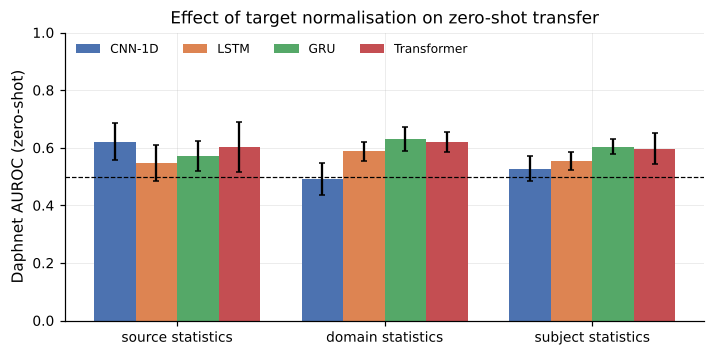

In [7]:
abl = res_dap.groupby(["normalisation", "arch"], sort=False)[["auroc", "auprc", "recall", "fpr"]].mean()
abl = abl.reindex(pd.MultiIndex.from_product([list(DV), C.ARCHS]))
abl.to_csv(C.METRICS / "daphnet_normalisation_ablation.csv")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
w = 0.2
for i, arch in enumerate(C.ARCHS):
    d = res_dap[res_dap.arch == arch].groupby("normalisation", sort=False).auroc
    ax.bar(np.arange(3) + (i - 1.5) * w, d.mean().reindex(list(DV)), w, yerr=d.std().reindex(list(DV)),
           color=C.PALETTE[arch], label=arch, capsize=2)
ax.axhline(0.5, ls="--", c="k", lw=0.8)
ax.set_xticks(range(3), list(DV))
ax.set_ylabel("Daphnet AUROC (zero-shot)")
ax.set_title("Effect of target normalisation on zero-shot transfer")
ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper left")
ax.set_ylim(0, 1)
save(fig, "fig13_normalisation_ablation")

## 5. ROC and PR curves (seed-averaged scores)

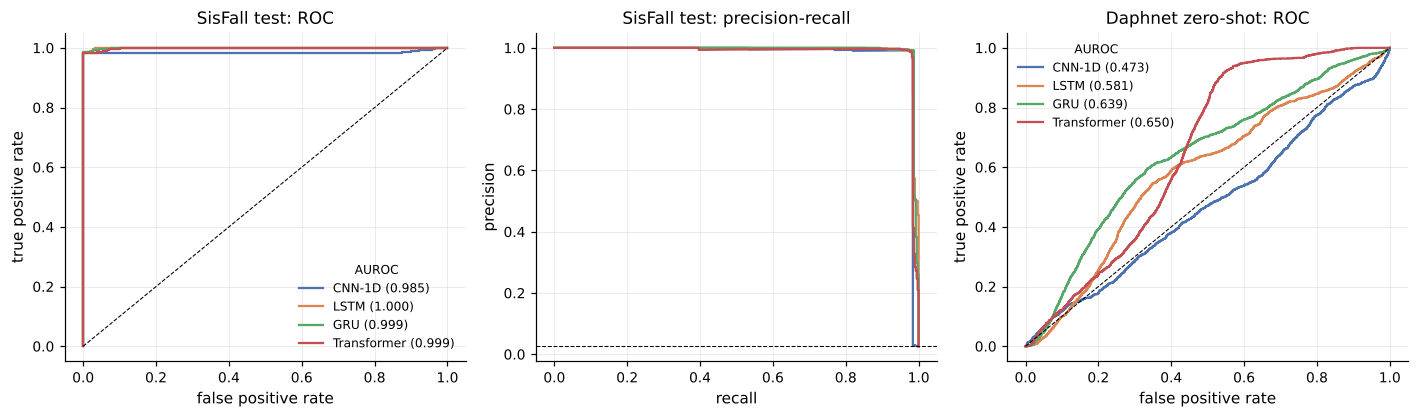

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for arch in C.ARCHS:
    p_t = np.mean([preds[(arch, s, "test")] for s in C.SEEDS], axis=0)
    p_d = np.mean([preds[(arch, s, "domain statistics")] for s in C.SEEDS], axis=0)
    f, t, _ = roc_curve(S["test"]["y"], p_t)
    axes[0].plot(f, t, color=C.PALETTE[arch], label=f"{arch} ({roc_auc_score(S['test']['y'], p_t):.3f})")
    pr, rc, _ = precision_recall_curve(S["test"]["y"], p_t)
    axes[1].plot(rc, pr, color=C.PALETTE[arch], label=arch)
    f, t, _ = roc_curve(y_dap, p_d)
    axes[2].plot(f, t, color=C.PALETTE[arch], label=f"{arch} ({roc_auc_score(y_dap, p_d):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.7)
axes[2].plot([0, 1], [0, 1], "k--", lw=0.7)
axes[1].axhline(S["test"]["y"].mean(), ls="--", c="k", lw=0.7)
axes[0].set(title="SisFall test: ROC", xlabel="false positive rate", ylabel="true positive rate")
axes[1].set(title="SisFall test: precision-recall", xlabel="recall", ylabel="precision")
axes[2].set(title="Daphnet zero-shot: ROC", xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(frameon=False, fontsize=8, title="AUROC", title_fontsize=8)
axes[2].legend(frameon=False, fontsize=8, title="AUROC", title_fontsize=8)
fig.tight_layout()
save(fig, "fig14_roc_pr_curves")

## 6. Confusion matrices (summed over the three seeds)

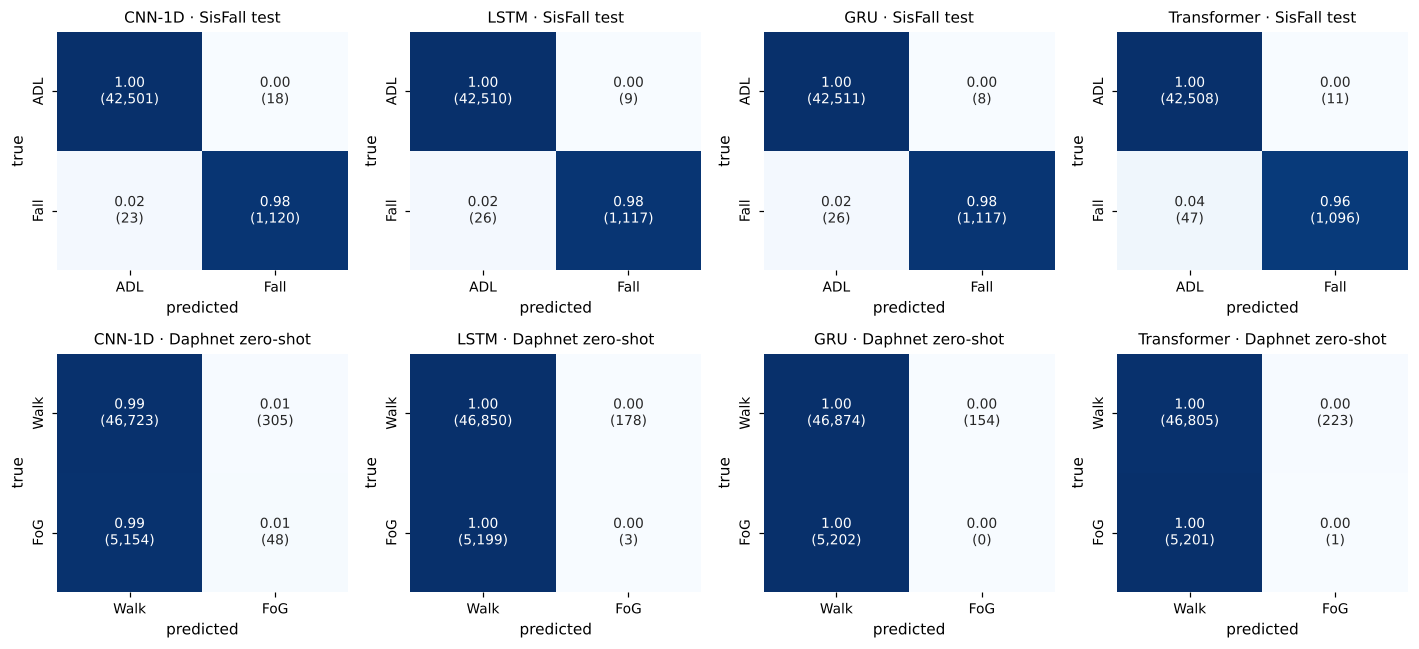

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for j, arch in enumerate(C.ARCHS):
    for i, (df, title, labels) in enumerate([
            (res_test[res_test.arch == arch], "SisFall test", ["ADL", "Fall"]),
            (main[main.arch == arch], "Daphnet zero-shot", ["Walk", "FoG"])]):
        cm = np.array([[df.tn.sum(), df.fp.sum()], [df.fn.sum(), df.tp.sum()]])
        cmn = cm / cm.sum(1, keepdims=True)
        ax = axes[i, j]
        sns.heatmap(cmn, annot=np.array([[f"{cmn[a, b]:.2f}\n({cm[a, b]:,})" for b in range(2)] for a in range(2)]),
                    fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                    xticklabels=labels, yticklabels=labels, annot_kws={"size": 9})
        ax.set_title(f"{arch} · {title}", fontsize=10)
        ax.set_xlabel("predicted")
        ax.set_ylabel("true")
        np.savetxt(C.CONFUSION / f"cm_{arch.replace('-', '').lower()}_{'sisfall' if i == 0 else 'daphnet'}.csv",
                   cm, fmt="%d", delimiter=",", header="rows=true [neg,pos], cols=pred [neg,pos]")
fig.tight_layout()
save(fig, "fig15_confusion_matrices")

## 7. Comparative summary and score distributions

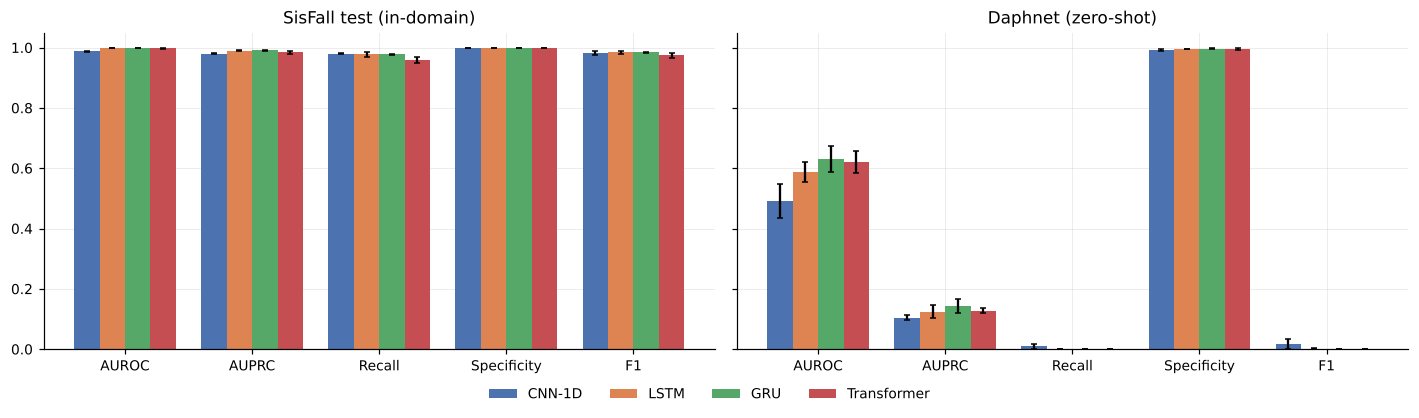

In [10]:
mets = ["auroc", "auprc", "recall", "specificity", "f1"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, df, title in [(axes[0], res_test, "SisFall test (in-domain)"), (axes[1], main, "Daphnet (zero-shot)")]:
    for i, arch in enumerate(C.ARCHS):
        g = df[df.arch == arch][mets]
        ax.bar(np.arange(len(mets)) + (i - 1.5) * 0.2, g.mean(), 0.2, yerr=g.std(), capsize=2,
               color=C.PALETTE[arch], label=arch)
    ax.set_xticks(range(len(mets)), ["AUROC", "AUPRC", "Recall", "Specificity", "F1"])
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
save(fig, "fig16_metric_comparison")

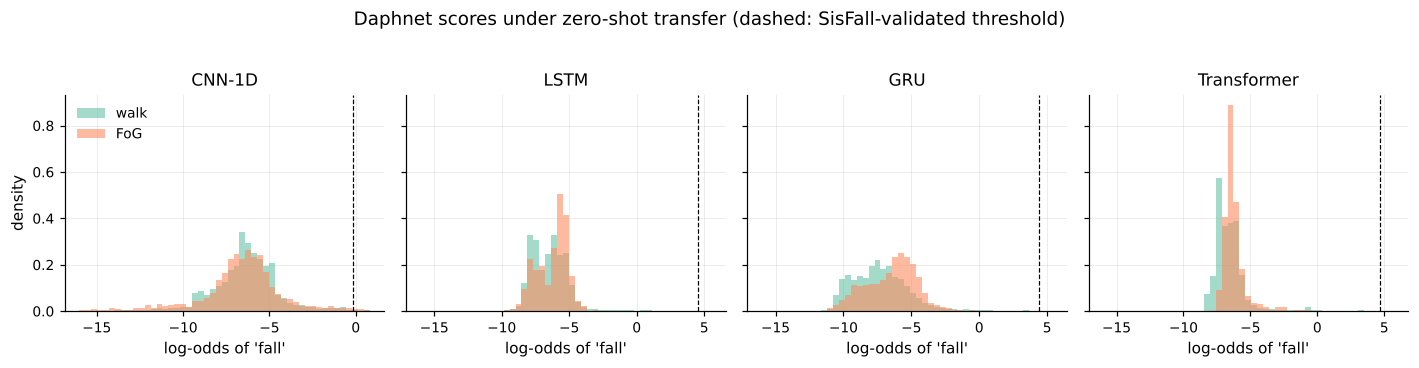

In [11]:
# Almost every Daphnet window gets a probability close to 0, so the scores are shown as
# log-odds, where the ranking between walking and FoG (what AUROC measures) is visible.
def logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))


fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, arch in zip(axes, C.ARCHS):
    z = logit(np.mean([preds[(arch, s, "domain statistics")] for s in C.SEEDS], axis=0))
    thr = logit(runs[runs.arch == arch].threshold.mean())
    bins = np.linspace(min(np.percentile(z, 0.5), -16), max(thr + 1, np.percentile(z, 99.5)), 50)
    ax.hist(z[y_dap == 0], bins=bins, density=True, alpha=0.6, color="#66C2A5", label="walk")
    ax.hist(z[y_dap == 1], bins=bins, density=True, alpha=0.6, color="#FC8D62", label="FoG")
    ax.axvline(thr, ls="--", c="k", lw=0.8)
    ax.set_title(arch)
    ax.set_xlabel("log-odds of 'fall'")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False)
fig.suptitle("Daphnet scores under zero-shot transfer (dashed: SisFall-validated threshold)", y=1.03)
fig.tight_layout()
save(fig, "fig17_daphnet_score_distributions")

## 8. Per-patient zero-shot AUROC

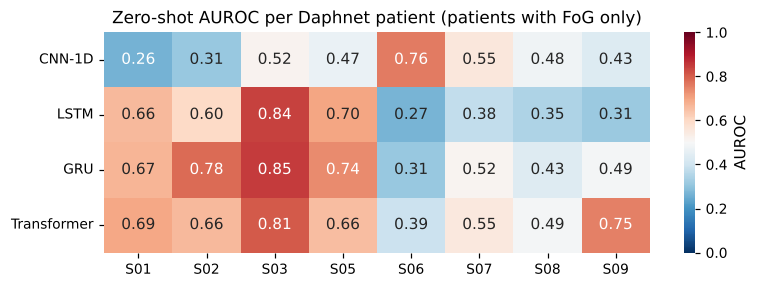

subject,S01,S02,S03,S05,S06,S07,S08,S09
arch,,,,,,,,
CNN-1D,0.265,0.310,0.519,0.468,0.758,0.555,0.480,0.431
LSTM,0.661,0.598,0.841,0.696,0.266,0.379,0.347,0.314
GRU,0.672,0.783,0.852,0.736,0.311,0.515,0.434,0.489
Transformer,0.695,0.662,0.806,0.655,0.393,0.552,0.490,0.752


In [12]:
rows = []
for arch in C.ARCHS:
    p = np.mean([preds[(arch, s, "domain statistics")] for s in C.SEEDS], axis=0)
    for subj, g in meta_dap.groupby("subject"):
        yy = g.label.values
        if yy.sum() == 0:
            continue
        rows.append({"arch": arch, "subject": subj, "auroc": roc_auc_score(yy, p[g.index.values]),
                     "fog_windows": int(yy.sum())})
per_subj = pd.DataFrame(rows)
per_subj.to_csv(C.METRICS / "daphnet_per_subject_auroc.csv", index=False)
piv = per_subj.pivot(index="arch", columns="subject", values="auroc").loc[C.ARCHS]
fig, ax = plt.subplots(figsize=(8, 2.6))
sns.heatmap(piv, annot=True, fmt=".2f", cmap="RdBu_r", center=0.5, vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "AUROC"})
ax.set_title("Zero-shot AUROC per Daphnet patient (patients with FoG only)")
ax.set_xlabel("")
ax.set_ylabel("")
save(fig, "fig18_per_patient_auroc")
piv.round(3)

In [13]:
summary = pd.DataFrame({
    "params": runs.groupby("arch").params.first(),
    "sec/epoch": runs.groupby("arch").sec_per_epoch.mean().round(1),
    "SisFall AUROC": res_test.groupby("arch").auroc.mean(),
    "SisFall AUPRC": res_test.groupby("arch").auprc.mean(),
    "SisFall recall": res_test.groupby("arch").recall.mean(),
    "SisFall FPR": res_test.groupby("arch").fpr.mean(),
    "Daphnet AUROC": main.groupby("arch").auroc.mean(),
    "Daphnet AUPRC": main.groupby("arch").auprc.mean(),
    "Daphnet recall": main.groupby("arch").recall.mean(),
    "Daphnet FPR": main.groupby("arch").fpr.mean(),
}).loc[C.ARCHS]
summary.to_csv(C.METRICS / "headline_results.csv")
summary.round(4)

,params,sec/epoch,SisFall AUROC,SisFall AUPRC,SisFall recall,SisFall FPR,Daphnet AUROC,Daphnet AUPRC,Daphnet recall,Daphnet FPR
arch,,,,,,,,,,
CNN-1D,36289,1.9,0.9875,0.9805,0.9799,0.0004,0.4910,0.1038,0.0092,0.0065
LSTM,135425,4.2,0.9994,0.9904,0.9773,0.0002,0.5874,0.1240,0.0006,0.0038
GRU,26241,2.2,0.9993,0.9916,0.9773,0.0002,0.6310,0.1430,0.0000,0.0033
Transformer,70401,2.7,0.9979,0.9842,0.9589,0.0003,0.6197,0.1282,0.0002,0.0047
